# Retail Customer & Sales Analysis

An analysis of sales, customers, products, and cancellations for an online retailer, preserving the scope of the original project.

## Business problem
Which products, customers, and markets drive merchandise sales, and how do cancellations and unusual orders affect performance? The analysis supports inventory prioritization, customer retention, and return monitoring.

## Context and methods
The two supplied CSV files contain invoice-line transactions. Combine them without double-counting their overlapping dates, remove exact duplicates, and separate merchandise sales from returns and administrative entries. Customer analysis uses identified customers only. Year comparisons use January–November in both years because December 2011 is incomplete.

### Key assumptions
- Exact duplicate rows are treated as repeated records; genuine identical invoice lines could also be removed.
- The original project's explicit adjustment-code lists are retained, rather than excluding every unusual stock-code format.
- C-prefixed invoices are cancellation/return records, not proof of matched returns to specific sales.
- Return ratios compare recorded returns with recorded sales in the observation window; they are not cohort return probabilities.
- Values are reported as source price units. The supplied CSV files do not document a currency, so no currency conversion or symbol is assumed.

## Setup
Install `requirements.txt`, launch Jupyter from the project folder, open this notebook, and choose **Restart Kernel → Run All**. Inputs are in `data/`; generated Tableau data and figures are written to `generated/`.

## At a glance

- Gross merchandise revenue is 19,643,861.64; recorded return value is 716,462.57; observed net merchandise revenue is 18,927,399.07 source price units.

- Returned value equals 3.65% of gross sales; returned units equal 4.18% of sold units.

- The top 10% of products (rounded down to 489) generate 62.55% of revenue. Prioritize availability for these products while monitoring reliance on exceptional orders.

- Identified customers account for 86.89% of gross sales. Customer behavior findings apply only to this identifiable subset.

- The two largest cancellation invoices account for 34.29% of return value. Investigate these individually before treating aggregate spikes as broad customer behavior.

- January–November gross revenue changed by 3.00% from 2010 to 2011. Compare the invoice count, customers, units, and order-value distribution together before inferring growth in demand.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, pearsonr, spearmanr
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
DATA = ROOT / 'data'
OUT = ROOT / 'generated'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE = '#2864A0', '#C77824'
pd.set_option('display.max_rows', 15)
pd.set_option('display.max_columns', 12)
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    display(Image(filename=str(OUT / f'{name}.png')))
    plt.close()


## Data
The supplied files are `online_retail_I.csv` and `online_retail_II.csv`. The original download URL and license were not supplied. Each row describes an invoice line with invoice number, stock code, description, quantity, invoice date, price, customer ID, and country. Missing customer IDs remain missing.

In [2]:
dtypes = {c: 'string' for c in ['Invoice', 'StockCode', 'Description', 'Country']}
df1 = pd.read_csv(DATA / 'online_retail_I.csv', dtype=dtypes)
df2 = pd.read_csv(DATA / 'online_retail_II.csv', dtype=dtypes)
required = {'Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country'}
for frame in (df1, df2):
    assert required <= set(frame.columns)
    frame['InvoiceDate'] = pd.to_datetime(frame['InvoiceDate'], errors='raise')
    frame['Customer ID'] = frame['Customer ID'].astype('Int64')
display(pd.DataFrame({'File': ['I', 'II'], 'Rows': [len(df1), len(df2)],
                      'Start': [df1.InvoiceDate.min(), df2.InvoiceDate.min()],
                      'End': [df1.InvoiceDate.max(), df2.InvoiceDate.max()]}))
display(df1.head(3))

,File,Rows,Start,End
0,I,525461,2009-12-01 07:45:00,2010-12-09 20:01:00
1,II,541910,2010-12-01 08:26:00,2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom


### Overlap and initial audit
Check equality of the overlapping records, including multiplicity, before retaining the second file for the overlapping period. Stop if the overlap differs rather than silently dropping unique records.

In [3]:
cutoff = df2.InvoiceDate.min()
overlap_end = df1.InvoiceDate.max()
left = df1[df1.InvoiceDate.between(cutoff, overlap_end)]
right = df2[df2.InvoiceDate.between(cutoff, overlap_end)]
h1 = pd.util.hash_pandas_object(left, index=False).value_counts().sort_index()
h2 = pd.util.hash_pandas_object(right, index=False).value_counts().sort_index()
assert h1.equals(h2), 'Overlapping extracts differ; investigate before combining.'
df_raw = pd.concat([df1[df1.InvoiceDate < cutoff], df2], ignore_index=True)
audit = pd.DataFrame({'Missing rows': df_raw.isna().sum(),
                      'Missing %': df_raw.isna().mean().mul(100).round(2)})
display(audit)
print(f'Combined rows: {len(df_raw):,}; exact duplicate rows: {df_raw.duplicated().sum():,}')

Combined rows: 1,044,848; exact duplicate rows: 11,812


,Missing rows,Missing %
Invoice,0,0.00
StockCode,0,0.00
Description,4275,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,235287,22.52
Country,0,0.00


## Data-cleaning decisions
Remove exact duplicates. Sales require a non-cancellation invoice, positive quantity, positive price, and a stock code outside the sales adjustment list. Returns use C-prefixed invoices outside the original cancellation adjustment list, with negative quantity and positive price validated below. Keep missing customer IDs for sales totals but exclude them from customer profiles. Zero-price entries, inventory corrections, and bad-debt adjustments do not contribute to merchandise revenue. Description capitalization is useful during exploration but is not a reliable product classifier.

In [4]:
sales_adjustments = ['M','D','BANK CHARGES','POST','DOT','S','C2','AMAZONFEE','TEST001',
 'TEST002','CRUK','gift_0001_80','ADJUST','ADJUST2','gift_0001_20','gift_0001_10',
 'gift_0001_50','gift_0001_30','gift_0001_70','gift_0001_40','B','m']
return_adjustments = ['M','D','BANK CHARGES','POST','DOT','S','C2','AMAZONFEE',
 'TEST001','CRUK','gift_0001_80','ADJUST']
df = df_raw.drop_duplicates().copy()
cancelled = df.Invoice.str.startswith('C', na=False)
sales_mask = ~cancelled & df.Quantity.gt(0) & df.Price.gt(0) & ~df.StockCode.isin(sales_adjustments)
return_mask = cancelled & ~df.StockCode.isin(return_adjustments)
df_sales = df.loc[sales_mask].copy()
df_returned = df.loc[return_mask].copy()
assert df_returned.Quantity.lt(0).all() and df_returned.Price.gt(0).all()
df_sales['revenue'] = df_sales.Quantity * df_sales.Price
df_returned['Return_Quantity'] = -df_returned.Quantity
df_returned['Return_Value'] = df_returned.Return_Quantity * df_returned.Price
customer_sales = df_sales[df_sales['Customer ID'].notna()].copy()
assert not df_sales.duplicated().any()
assert len(df_sales) + len(df_returned) + len(df.loc[~(sales_mask | return_mask)]) == len(df)
display(pd.Series({'Raw combined': len(df_raw), 'Duplicates removed': len(df_raw)-len(df),
 'Sales': len(df_sales), 'Returns': len(df_returned),
 'Other excluded records': (~(sales_mask | return_mask)).sum()}, name='Rows').to_frame())

,Rows
Raw combined,1044848
Duplicates removed,11812
Sales,1003357
Returns,17915
Other excluded records,11764


## Results
### Sales and return overview
Gross revenue is positive merchandise sales; return value is a positive magnitude. Observed net merchandise revenue is gross revenue minus return value. It excludes fees, postage, tax information, costs, and other adjustments, so it is not profit or accounting revenue.

In [5]:
gross = df_sales.revenue.sum()
returns = df_returned.Return_Value.sum()
invoices = df_sales.groupby('Invoice').agg(revenue=('revenue','sum'), InvoiceDate=('InvoiceDate','min'))
kpis = {'Gross merchandise revenue': gross, 'Return value': returns,
 'Observed net merchandise revenue': gross-returns, 'Sales invoices': len(invoices),
 'Identified customers': df_sales['Customer ID'].nunique(), 'Products sold': df_sales.StockCode.nunique(),
 'Units sold': df_sales.Quantity.sum(), 'Returned value / gross sales (%)': returns/gross*100,
 'Returned units / sold units (%)': df_returned.Return_Quantity.sum()/df_sales.Quantity.sum()*100,
 'Mean order value': invoices.revenue.mean(), 'Median order value': invoices.revenue.median()}
display(pd.Series(kpis, name='Value').round(2).to_frame())

,Value
Gross merchandise revenue,19643861.64
Return value,716462.57
Observed net merchandise revenue,18927399.07
Sales invoices,39516.00
Identified customers,5852.00
Products sold,4896.00
Units sold,11188061.00
Returned value / gross sales (%),3.65
Returned units / sold units (%),4.18
Mean order value,497.11


### Revenue over time
Show all observed months and flag December 2011 as partial. Sales and returns use the same monthly index.

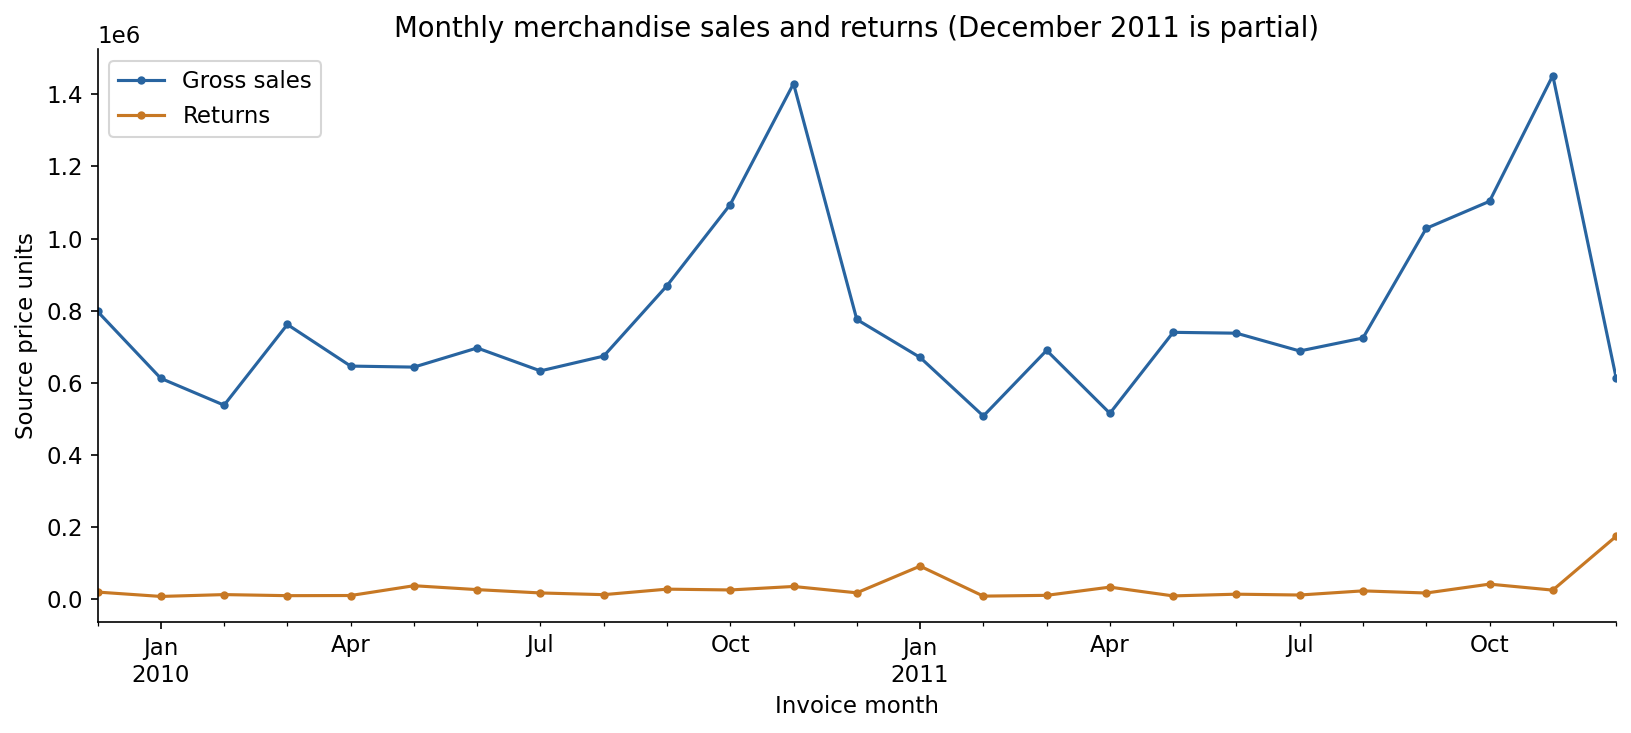

,Gross sales,Returns
InvoiceDate,,
2011-10,1103314.25,41613.03
2011-11,1452115.98,24991.44
2011-12,614490.92,174091.36


In [6]:
monthly = pd.concat([
 df_sales.groupby(df_sales.InvoiceDate.dt.to_period('M')).revenue.sum().rename('Gross sales'),
 df_returned.groupby(df_returned.InvoiceDate.dt.to_period('M')).Return_Value.sum().rename('Returns')], axis=1)
ax = monthly.set_axis(monthly.index.to_timestamp()).plot(color=[BLUE, ORANGE], marker='o', markersize=3)
ax.set(title='Monthly merchandise sales and returns (December 2011 is partial)', xlabel='Invoice month', ylabel='Source price units')
savefig('monthly_revenue')
display(monthly.tail(3).round(2))

### Order-value distribution and geography
Retain exceptional orders in totals. Use a log axis to show the skewed order-value distribution without dropping high-value orders. Country revenue measures the invoiced country, not customer nationality.

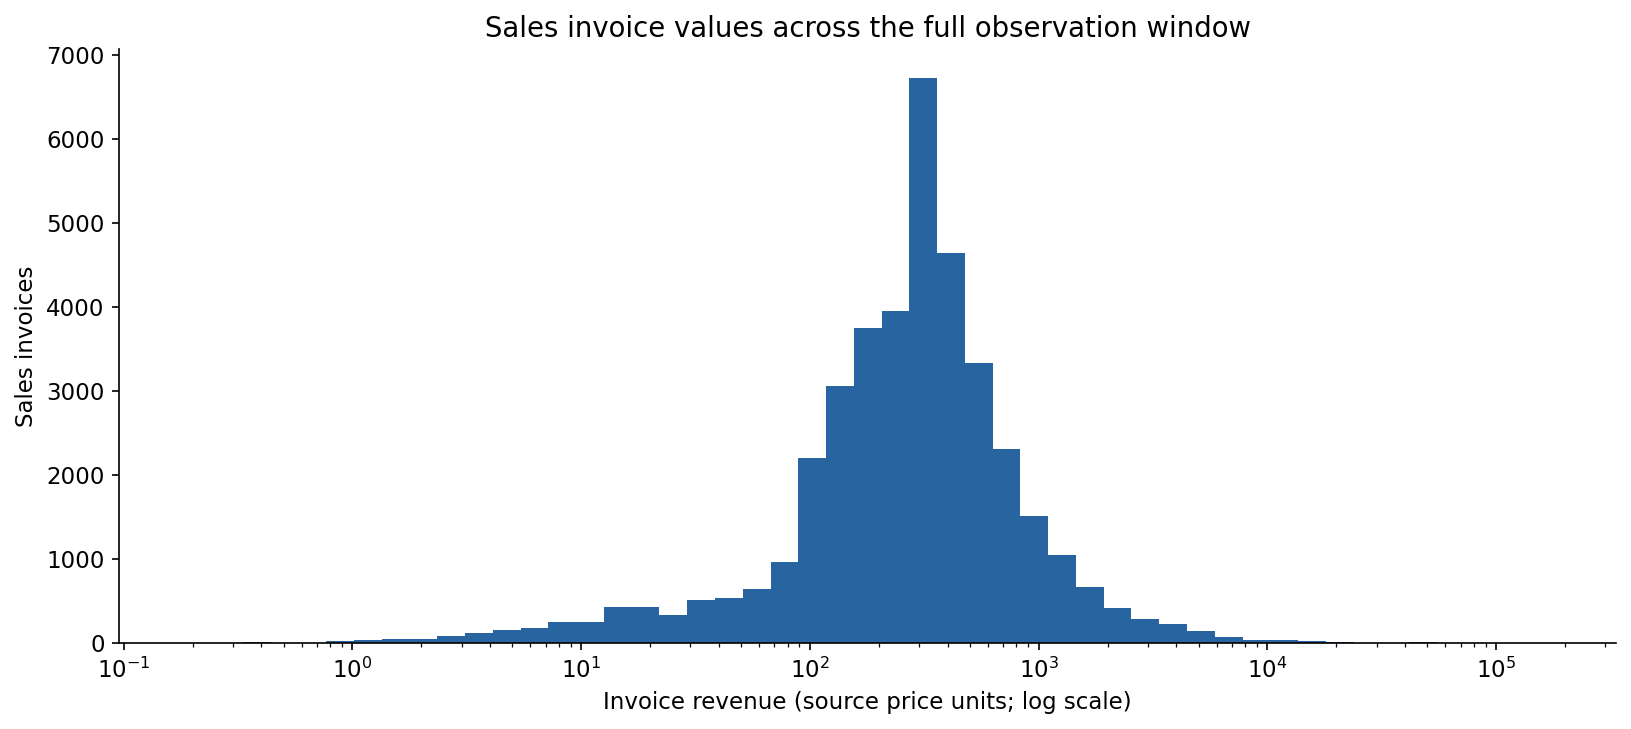

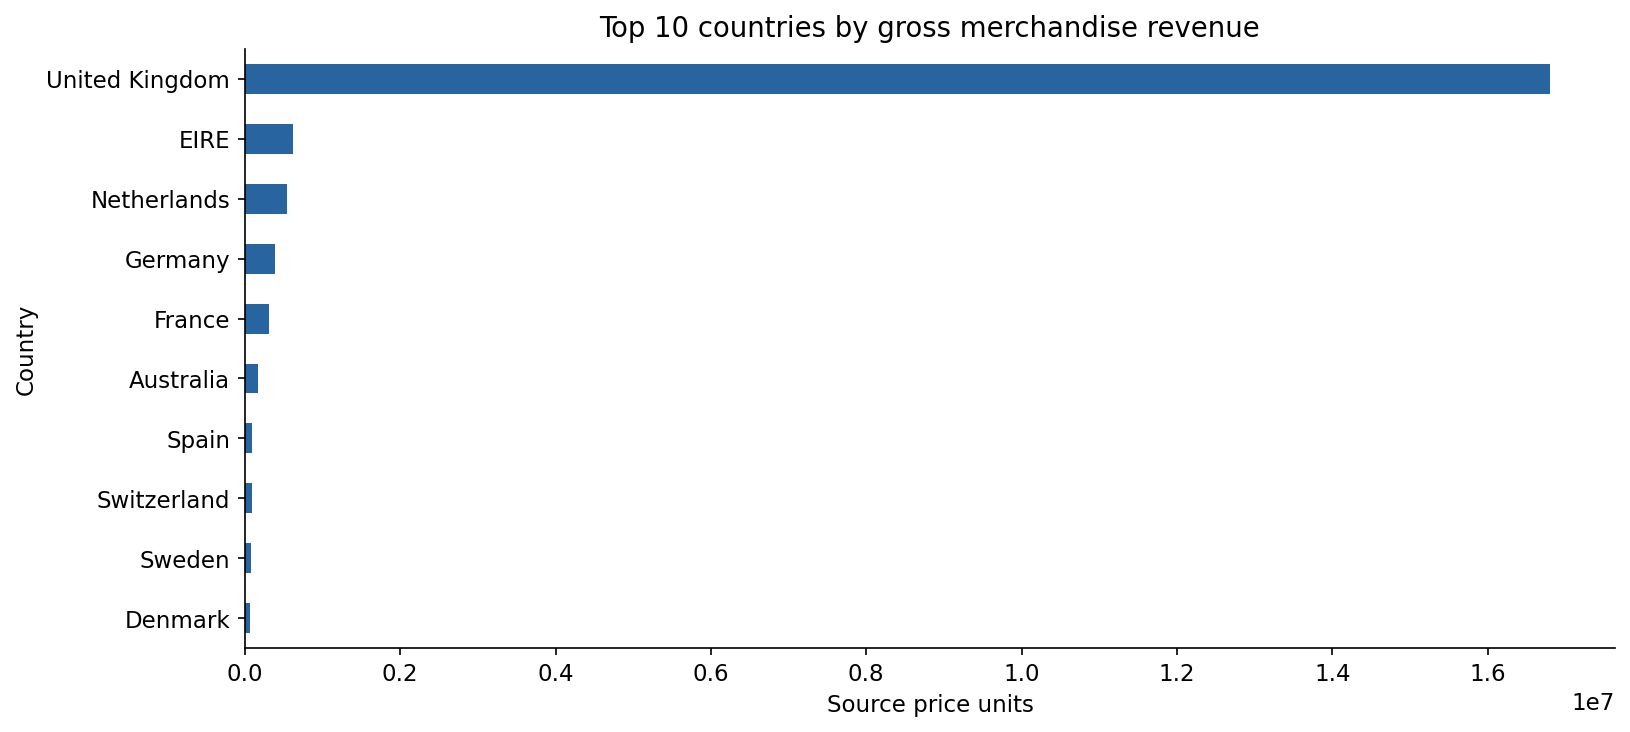

In [7]:
plt.hist(invoices.revenue, bins=np.geomspace(invoices.revenue.min(), invoices.revenue.max(), 50), color=BLUE)
plt.xscale('log')
plt.title('Sales invoice values across the full observation window')
plt.xlabel('Invoice revenue (source price units; log scale)')
plt.ylabel('Sales invoices')
savefig('order_distribution')
country_revenue = df_sales.groupby('Country').revenue.sum().sort_values(ascending=False)
country_revenue.head(10).sort_values().plot.barh(color=BLUE)
plt.title('Top 10 countries by gross merchandise revenue')
plt.xlabel('Source price units')
savefig('country_revenue')

### Customer coverage, concentration, and frequency
Missing customer IDs prevent identification of distinct anonymous customers and their repeat behavior. Compare invoice values for identified versus unidentified records, but do not interpret anonymous invoices as distinct customers.

Identified customer revenue coverage: 86.89%
Top 585 identified customers: 63.86% of identified-customer sales


,Invoice_Count,Total_Revenue,Total_Quantity,First_Purchase,Last_Purchase
Customer ID,,,,,
18102,145,580987.04,181645,2009-12-01 09:24:00,2011-12-09 11:50:00
14646,145,526751.52,367072,2009-12-02 16:52:00,2011-12-08 12:12:00
14156,144,303069.88,164281,2009-12-01 12:30:00,2011-11-30 10:54:00
14911,373,272252.79,147804,2009-12-01 11:41:00,2011-12-08 15:54:00
17450,51,244784.25,83914,2010-09-27 16:59:00,2011-12-01 13:29:00
13694,143,195640.69,188201,2009-12-04 15:26:00,2011-12-06 09:32:00
17511,60,172132.87,117174,2009-12-02 10:52:00,2011-12-07 10:12:00
16446,2,168472.50,80997,2011-05-18 09:52:00,2011-12-09 09:15:00
16684,55,147142.77,104810,2009-12-07 12:56:00,2011-12-05 14:06:00


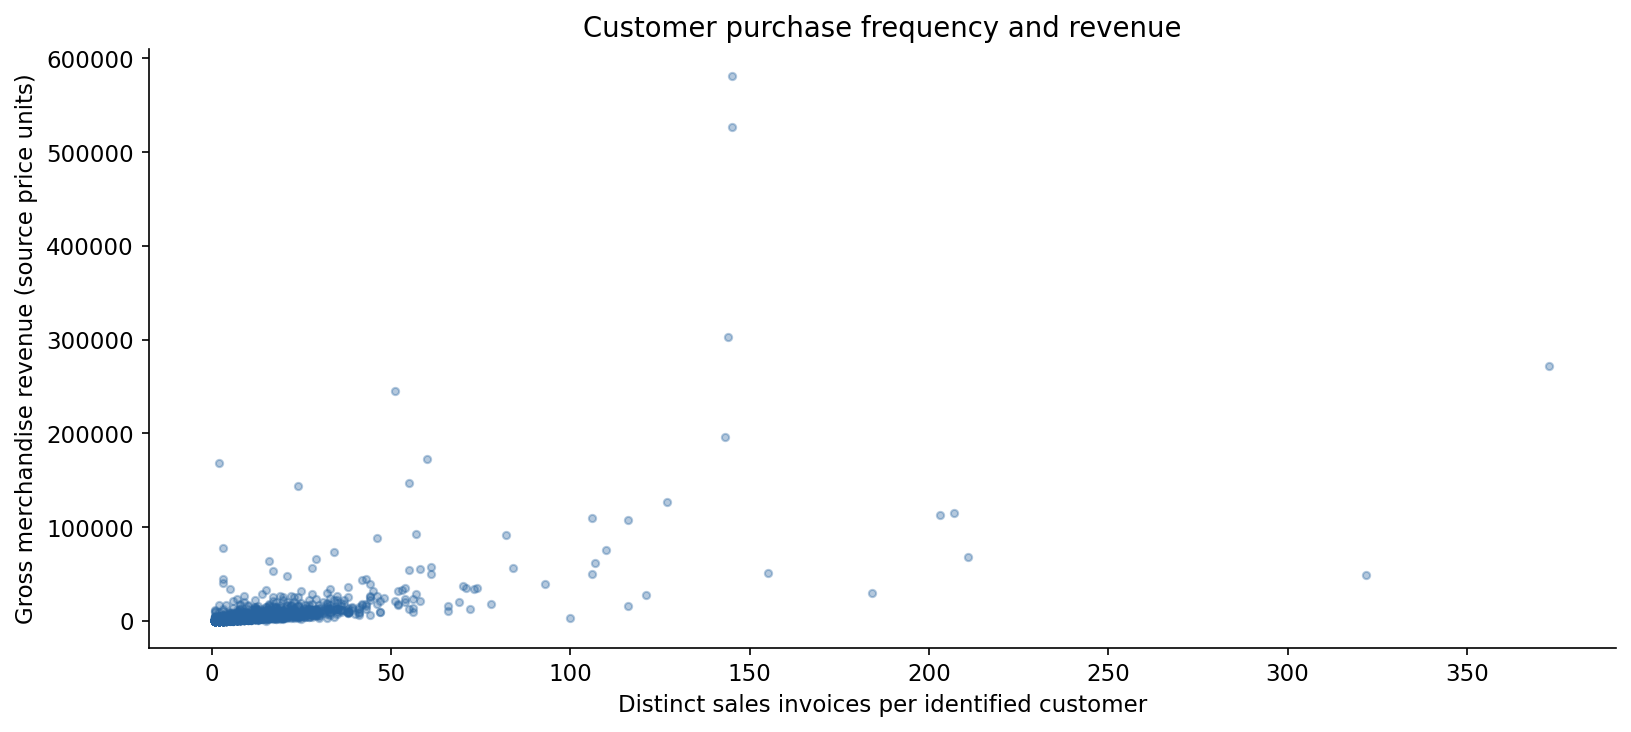

In [8]:
customer_summary = customer_sales.groupby('Customer ID').agg(
 Invoice_Count=('Invoice','nunique'), Total_Revenue=('revenue','sum'),
 Total_Quantity=('Quantity','sum'), First_Purchase=('InvoiceDate','min'), Last_Purchase=('InvoiceDate','max'))
coverage = customer_sales.revenue.sum()/gross*100
top_customer_count = max(1, int(len(customer_summary)*0.1))
customer_concentration = customer_summary.Total_Revenue.nlargest(top_customer_count).sum()/customer_summary.Total_Revenue.sum()*100
print(f'Identified customer revenue coverage: {coverage:.2f}%')
print(f'Top {top_customer_count:,} identified customers: {customer_concentration:.2f}% of identified-customer sales')
display(customer_summary.sort_values('Total_Revenue', ascending=False).head(10))
plt.scatter(customer_summary.Invoice_Count, customer_summary.Total_Revenue, alpha=.35, s=12, color=BLUE)
plt.xlabel('Distinct sales invoices per identified customer')
plt.ylabel('Gross merchandise revenue (source price units)')
plt.title('Customer purchase frequency and revenue')
savefig('customer_frequency')

### Product performance
Assess revenue, quantity, invoice frequency, and customer reach separately. A product with one exceptional order is not necessarily broadly popular.

Top 489 products (10.0% of catalog) generate 62.55% of gross revenue.


,Total_revenue,Total_Quantity,Invoice_Count,Customer_Count
StockCode,,,,
22423,330590.32,26478,3918,1314
85123A,257724.71,94203,5365,1490
85099B,180569.34,96757,3989,978
23843,168469.60,80995,1,1
47566,148318.28,28200,2674,894
84879,129324.49,80082,2807,1010
22086,117760.29,35084,2018,896
23166,81700.92,78033,247,138
79321,80540.88,15841,1135,304


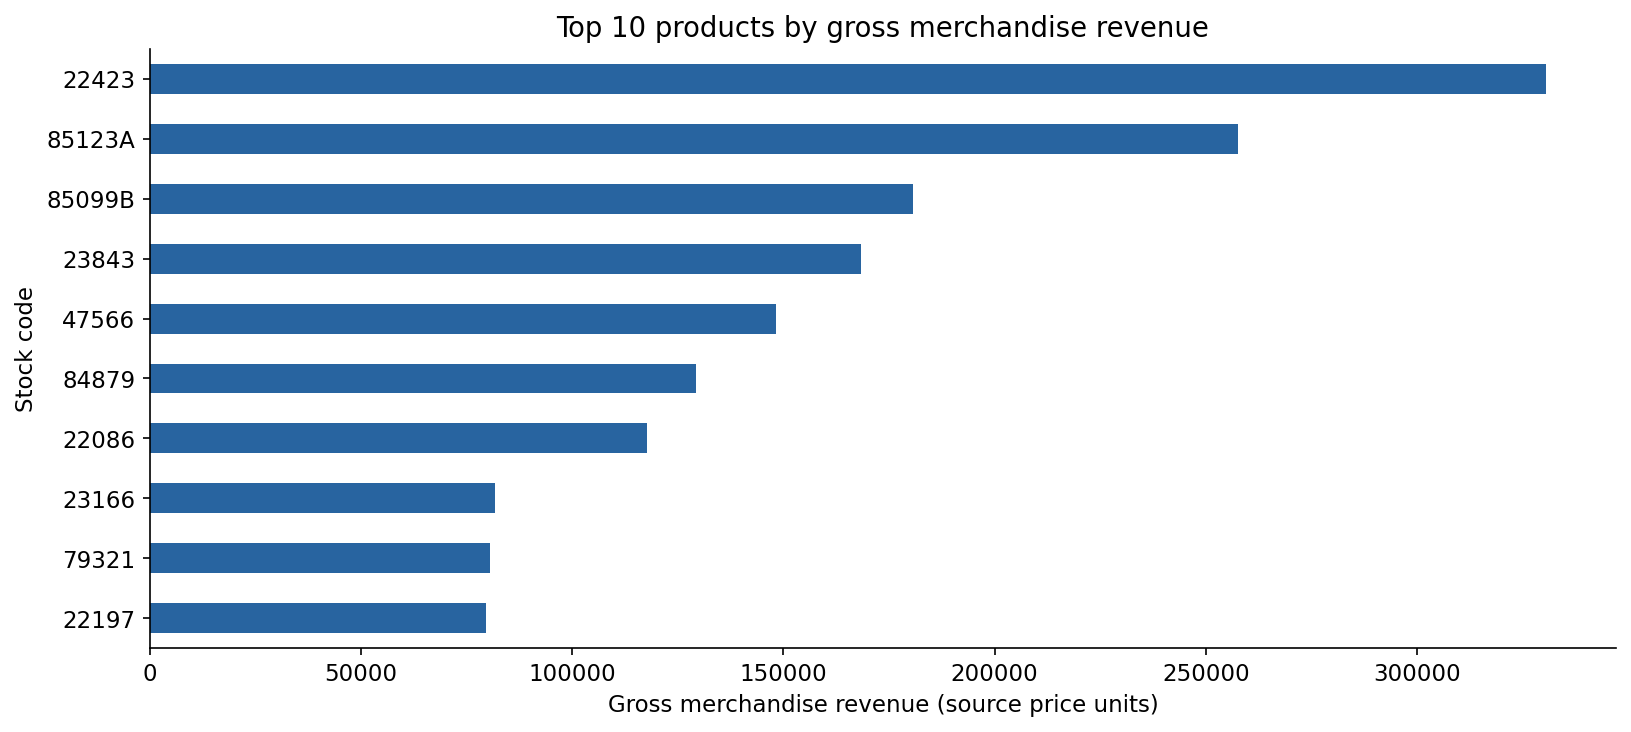

In [9]:
products_summary = df_sales.groupby('StockCode').agg(Total_revenue=('revenue','sum'),
 Total_Quantity=('Quantity','sum'), Invoice_Count=('Invoice','nunique'), Customer_Count=('Customer ID','nunique'))
top_product_count = max(1, int(len(products_summary)*0.1))
product_concentration = products_summary.Total_revenue.nlargest(top_product_count).sum()/gross*100
display(products_summary.sort_values('Total_revenue', ascending=False).head(10))
print(f'Top {top_product_count} products ({top_product_count/len(products_summary):.1%} of catalog) generate {product_concentration:.2f}% of gross revenue.')
products_summary.Total_revenue.nlargest(10).sort_values().plot.barh(color=BLUE)
plt.xlabel('Gross merchandise revenue (source price units)')
plt.ylabel('Stock code')
plt.title('Top 10 products by gross merchandise revenue')
savefig('product_revenue')

### Returns and exceptional cancellations
Compare returned value, units, invoice counts, and customer reach. Ratios above 100% can reflect unmatched periods, classification issues, or original sales outside the window; the data does not establish a unique explanation. Preserve products without recorded returns in the comparison.

,Total_revenue,Total_Quantity,Invoice_Count,Customer_Count,Returned_quantity,Returned_value,Cancellation_invoices,Returning_customers,Returned value / recorded sales (%)
StockCode,,,,,,,,,
23843,168469.60,80995,1,1,80995.0,168469.60,1.0,1.0,100.000000
23166,81700.92,78033,247,138,74494.0,77479.64,10.0,10.0,94.833253
22423,330590.32,26478,3918,1314,1450.0,16545.30,341.0,195.0,5.004774
85123A,257724.71,94203,5365,1490,3637.0,9387.10,134.0,99.0,3.642297
71477,44680.75,15089,809,302,2574.0,7164.12,67.0,43.0,16.034019
21108,25407.27,12962,613,325,3159.0,6614.37,4.0,4.0,26.033375
79323W,18048.72,3004,349,174,1088.0,6421.10,124.0,109.0,35.576484
21843,64918.30,6128,1527,599,587.0,5270.25,154.0,113.0,8.118281
84078A,43844.96,1128,328,151,147.0,5187.65,20.0,15.0,11.831805


,Return value,Share of all returned value (%)
Invoice,,
C581484,168469.60,23.514083
C541433,77183.60,10.772873
C550456,22998.40,3.209993
C524235,11880.84,1.658264
C570556,9466.56,1.321292
C513771,7500.32,1.046854
C529352,6325.08,0.882821
C508132,4815.80,0.672164
C508134,4798.80,0.669791


,Invoice_Count,Total_Revenue,Total_Quantity,First_Purchase,Last_Purchase,Return_value,Cancellation_invoices
Customer ID,,,,,,,
16446,2,168472.50,80997,2011-05-18 09:52:00,2011-12-09 09:15:00,168469.60,1.0
12346,3,77352.96,74239,2010-03-02 13:08:00,2011-01-18 10:01:00,77183.60,1.0
15749,3,44534.30,18028,2011-01-11 12:55:00,2011-04-18 13:20:00,22998.40,1.0
12931,57,92347.34,62906,2009-12-01 11:46:00,2011-11-18 12:39:00,20800.37,11.0
14911,373,272252.79,147804,2009-12-01 11:41:00,2011-12-08 15:54:00,13730.36,93.0
14277,8,16789.16,89802,2009-12-13 15:43:00,2011-11-24 15:01:00,12829.34,5.0
16029,106,109620.87,54449,2009-12-08 11:23:00,2011-11-01 10:27:00,12554.16,6.0
12454,4,16459.78,7702,2010-10-14 17:33:00,2011-10-14 17:13:00,12360.82,3.0
17450,51,244784.25,83914,2010-09-27 16:59:00,2011-12-01 13:29:00,11140.34,4.0


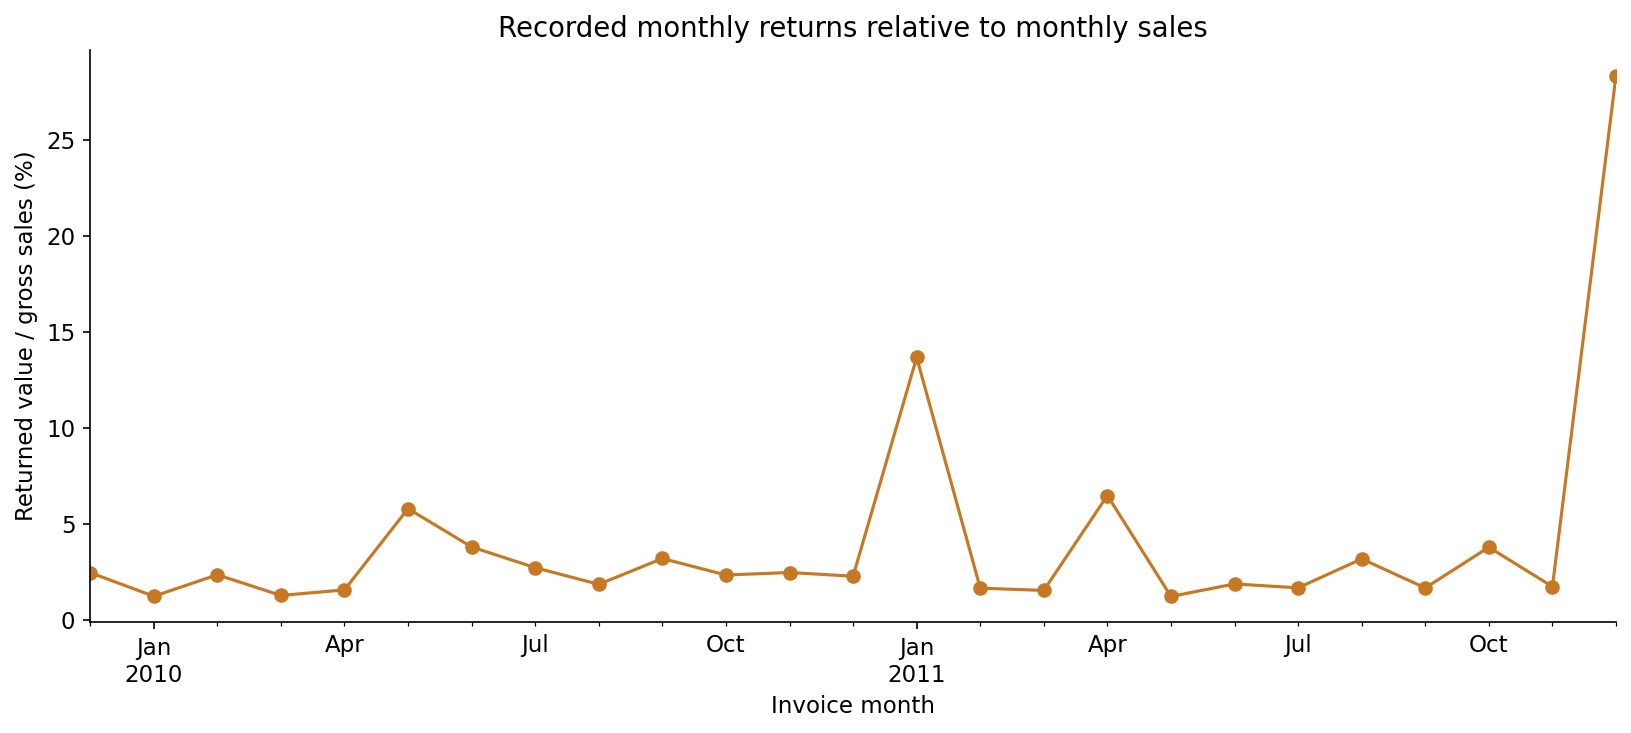

In [10]:
returned_summary = df_returned.groupby('StockCode').agg(Returned_quantity=('Return_Quantity','sum'),
 Returned_value=('Return_Value','sum'), Cancellation_invoices=('Invoice','nunique'),
 Returning_customers=('Customer ID','nunique'))
product_returns = products_summary.join(returned_summary, how='left').fillna(0)
product_returns['Returned value / recorded sales (%)'] = product_returns.Returned_value/product_returns.Total_revenue*100
display(product_returns.sort_values('Returned_value', ascending=False).head(10))
return_invoices = df_returned.groupby('Invoice').Return_Value.sum().sort_values(ascending=False)
display(pd.DataFrame({'Return value': return_invoices.head(10), 'Share of all returned value (%)': return_invoices.head(10)/returns*100}))
customer_returns = df_returned.dropna(subset=['Customer ID']).groupby('Customer ID').agg(
 Return_value=('Return_Value','sum'), Cancellation_invoices=('Invoice','nunique'))
display(customer_summary.join(customer_returns).fillna({'Return_value':0,'Cancellation_invoices':0})
        .sort_values('Return_value',ascending=False).head(10))
ax = monthly['Returns'].div(monthly['Gross sales']).mul(100).set_axis(monthly.index.to_timestamp()).plot(marker='o', color=ORANGE)
ax.set(title='Recorded monthly returns relative to monthly sales', xlabel='Invoice month', ylabel='Returned value / gross sales (%)')
savefig('monthly_return_ratio')

### Comparable year analysis: January–November
Exclude December from both years. This prevents the partial December 2011 extract from distorting the comparison. Returns are recorded by cancellation date and are not matched to the original purchase cohort.

In [11]:
comparison = {}
for year in (2010, 2011):
    sales = df_sales[(df_sales.InvoiceDate.dt.year==year) & (df_sales.InvoiceDate.dt.month<=11)]
    ret = df_returned[(df_returned.InvoiceDate.dt.year==year) & (df_returned.InvoiceDate.dt.month<=11)]
    orders = sales.groupby('Invoice').revenue.sum()
    comparison[year] = {'Gross revenue': sales.revenue.sum(), 'Sales invoices': len(orders),
     'Identified customers': sales['Customer ID'].nunique(), 'Units sold': sales.Quantity.sum(),
     'Mean order value': orders.mean(), 'Median order value': orders.median(), 'Returned value': ret.Return_Value.sum()}
comparison = pd.DataFrame(comparison)
comparison['Change (%)'] = (comparison[2011]/comparison[2010]-1)*100
display(comparison.round(2))

,2010,2011,Change (%)
Gross revenue,8598741.15,8857090.04,3.00
Sales invoices,18077.00,17407.00,-3.71
Identified customers,4127.00,4168.00,0.99
Units sold,5201456.00,4891211.00,-5.96
Mean order value,475.67,508.82,6.97
Median order value,300.35,303.68,1.11
Returned value,221003.33,284261.94,28.62


### Statistical analysis
Pearson and Spearman correlations describe association between customer purchase frequency and accumulated revenue; revenue also mechanically accumulates with orders. Welch’s two-sided test compares mean invoice revenue for January–November 2010 versus 2011, without assuming equal variances. Repeated customers, skew, and extreme orders limit an independent-invoice interpretation. This observational comparison does not establish causality.

In [12]:
pearson = pearsonr(customer_summary.Invoice_Count, customer_summary.Total_Revenue)
spearman = spearmanr(customer_summary.Invoice_Count, customer_summary.Total_Revenue)
a = invoices.loc[(invoices.InvoiceDate.dt.year==2010) & (invoices.InvoiceDate.dt.month<=11), 'revenue']
b = invoices.loc[(invoices.InvoiceDate.dt.year==2011) & (invoices.InvoiceDate.dt.month<=11), 'revenue']
test = ttest_ind(a, b, equal_var=False)
display(pd.Series({'Pearson r': pearson.statistic, 'Spearman rho': spearman.statistic,
 'Welch t (2010 minus 2011)': test.statistic, 'Welch two-sided p': test.pvalue,
 '2010 invoices': len(a), '2011 invoices': len(b)}, name='Result').to_frame())
display(Markdown(f'The mean order value changed by **{comparison.loc["Mean order value", "Change (%)"]:.2f}%**, '
 f'while the median changed by **{comparison.loc["Median order value", "Change (%)"]:.2f}%**. '
 'The difference between mean and median changes is consistent with a skewed order distribution; it does not by itself identify the cause.'))

,Result
Pearson r,0.619417
Spearman rho,0.859009
Welch t (2010 minus 2011),-2.580143
Welch two-sided p,0.009880
2010 invoices,18077.000000
2011 invoices,17407.000000


The mean order value changed by **6.97%**, while the median changed by **1.11%**. The difference between mean and median changes is consistent with a skewed order distribution; it does not by itself identify the cause.

## Takeaways and business implications

In [13]:
findings = [
 f'Gross merchandise revenue is {gross:,.2f}; recorded return value is {returns:,.2f}; observed net merchandise revenue is {gross-returns:,.2f} source price units.',
 f'Returned value equals {returns/gross:.2%} of gross sales; returned units equal {df_returned.Return_Quantity.sum()/df_sales.Quantity.sum():.2%} of sold units.',
 f'The top 10% of products (rounded down to {top_product_count}) generate {product_concentration:.2f}% of revenue. Prioritize availability for these products while monitoring reliance on exceptional orders.',
 f'Identified customers account for {coverage:.2f}% of gross sales. Customer behavior findings apply only to this identifiable subset.',
 f'The two largest cancellation invoices account for {return_invoices.head(2).sum()/returns:.2%} of return value. Investigate these individually before treating aggregate spikes as broad customer behavior.',
 f'January–November gross revenue changed by {comparison.loc["Gross revenue", "Change (%)"]:.2f}% from 2010 to 2011. Compare the invoice count, customers, units, and order-value distribution together before inferring growth in demand.'
]
display(Markdown('\n\n'.join('- '+x for x in findings)))

- Gross merchandise revenue is 19,643,861.64; recorded return value is 716,462.57; observed net merchandise revenue is 18,927,399.07 source price units.

- Returned value equals 3.65% of gross sales; returned units equal 4.18% of sold units.

- The top 10% of products (rounded down to 489) generate 62.55% of revenue. Prioritize availability for these products while monitoring reliance on exceptional orders.

- Identified customers account for 86.89% of gross sales. Customer behavior findings apply only to this identifiable subset.

- The two largest cancellation invoices account for 34.29% of return value. Investigate these individually before treating aggregate spikes as broad customer behavior.

- January–November gross revenue changed by 3.00% from 2010 to 2011. Compare the invoice count, customers, units, and order-value distribution together before inferring growth in demand.

## Tableau dashboard
[View the supplied Tableau Public profile](https://public.tableau.com/app/profile/mohmmadsadegh.rahmani/vizzes). The supplied URL is a profile, not a verified direct workbook link. The export below supports sales, returns, net merchandise revenue, products, countries, customers, and monthly views. No claim is made that a published workbook has been refreshed with this export.

In [14]:
columns = ['Invoice','StockCode','Description','Quantity','InvoiceDate','Price','Customer ID','Country']
tableau_sales = df_sales[columns].copy()
tableau_sales['Transaction_Type'] = 'Sale'
tableau_sales['Sales_Quantity'] = tableau_sales.Quantity
tableau_sales['Return_Quantity'] = 0
tableau_sales['Gross_Revenue'] = df_sales.revenue
tableau_sales['Return_Value'] = 0.0
tableau_returns = df_returned[columns].copy()
# Keep the original export convention: return Quantity is a positive magnitude.
tableau_returns['Quantity'] = df_returned.Return_Quantity
tableau_returns['Transaction_Type'] = 'Return'
tableau_returns['Sales_Quantity'] = 0
tableau_returns['Return_Quantity'] = df_returned.Return_Quantity
tableau_returns['Gross_Revenue'] = 0.0
tableau_returns['Return_Value'] = df_returned.Return_Value
tableau_data = pd.concat([tableau_sales, tableau_returns], ignore_index=True)
tableau_data['Net_Revenue'] = tableau_data.Gross_Revenue-tableau_data.Return_Value
tableau_data['Year'] = tableau_data.InvoiceDate.dt.year
tableau_data['Month'] = tableau_data.InvoiceDate.dt.month
tableau_data['Year_Month'] = tableau_data.InvoiceDate.dt.to_period('M').astype(str)
assert np.isclose(tableau_data.Net_Revenue.sum(), gross-returns)
assert np.isclose(tableau_data.Gross_Revenue.sum(), gross)
assert np.isclose(tableau_data.Return_Value.sum(), returns)
tableau_data.to_csv(OUT/'online_retail_tableau.csv', index=False)
display(tableau_data.groupby('Transaction_Type')[['Gross_Revenue','Return_Value','Net_Revenue']].sum().round(2))
metrics = {'kpis': {k:float(v) for k,v in kpis.items()}, 'findings':findings,
 'comparison':comparison.to_dict(), 'welch_p':float(test.pvalue),
 'date_start':str(df_raw.InvoiceDate.min()), 'date_end':str(df_raw.InvoiceDate.max()),
 'raw_rows':len(df_raw), 'sales_rows':len(df_sales), 'return_rows':len(df_returned)}
(OUT/'validated_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print('Validation passed; Tableau export saved to generated/online_retail_tableau.csv.')

Validation passed; Tableau export saved to generated/online_retail_tableau.csv.


,Gross_Revenue,Return_Value,Net_Revenue
Transaction_Type,,,
Return,0.00,716462.57,-716462.57
Sale,19643861.64,0.00,19643861.64


## Limitations
- Historical observational data cannot establish causal explanations or current trading performance.
- December 2011 ends on December 9; do not compare it with full December periods.
- Customer IDs are missing for a substantial subset; anonymous repeat behavior is unknown.
- Cancellations cannot be reliably paired with original sales from invoice prefixes alone.
- Exact-row deduplication and manual adjustment-code classification require business-owner confirmation.
- Extreme orders and cancellations materially affect averages and return ratios; they remain in reported totals.
- No cost, margin, marketing, inventory availability, or customer acquisition data is available.
- Source currency, original download URL, and redistribution license were not supplied. The README avoids asserting them.
- The Tableau profile was supplied by the author; a specific published workbook and its data freshness have not been verified.
